# Grid Contingency Analysis
## Which single failures hurt the grid? How does a failure spread? 

Import necessary packages.

---

In [9]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import pandapower as pp
import pandapower.networks as pn
import pandapower.topology as top
# import pandapower.plotting as plot

In [10]:
# load benchmark IEEE 14-bus network
net = pn.power_system_test_cases.case14()

# run standard AC power flow
pp.runpp(net)

# get all transmission lines, put in array
lines = net.line.index.tolist()
# plot.simple_plot(net, plot_loads=True, plot_gens=True)

Establish the N-0 case for the IEEE 14-bus system. This serves as a baseline for comparison for N-K contingencies.

In [11]:
# N-0 case (for comparison)
v_min, v_max, load_max = 0.95, 1.10, 100 # establish thresholds (limits) to evaluate grid, v_max increased to account for higher max bus voltage

# load buses
gen_buses = set(net.gen.bus) | set(net.ext_grid.bus) # id buses connected to generator and external grid, joins them
pq_buses = [bus for bus in net.bus.index if bus not in gen_buses] # keep buses that are not in gen_buses

# save placeholder limits (original ratings)
default_limits = net.line["max_i_ka"].copy()

# calculate S to determine how much power each line carries (reference for setting current limits)
vn = net.bus.vn_kv[net.line.from_bus].values # get the nominal voltage of the bus where each line begins
base_mva = np.sqrt(3) * vn * net.res_line.i_ka.values # 3-phase formula to find apparent power

# calculate new limits (current ratings) for the max value in each voltage group
for voltage_group in (vn > 100, vn < 100):
    max_mva = 1.5 * base_mva[voltage_group].max()
    net.line.loc[voltage_group, "max_i_ka"] = max_mva / (np.sqrt(3) * vn[voltage_group])

pp.runpp(net) # rerun power flow using new limits
# plot.simple_plot(net, plot_loads=True, plot_gens=True)

In [12]:
# check each line against the following conditions: 
# 1. min bus voltage < 0.95 pu
# 2. max bus voltage > 1.10 pu
# 3. number of overloaded > 0
# 4. number of islanded > 0

def check_case(net, n=1.0):
    v = net.res_bus.loc[pq_buses, "vm_pu"] # load buses
    loading = net.res_line["loading_percent"]

    # islanded grid, check separation from main network
    map = top.create_nxgraph(net) # map all true connections
    islands = list(top.connected_components(map))
    # n_islands = len(islands)
    n_islanded = len(top.unsupplied_buses(net))

    n_overload = int((loading > load_max).sum())
    violation = n_overload > 0 or v.min() < v_min or v.max() > v_max or n_islanded > 0
    perf_index_v = ((abs(v-1.0)/0.10)**(2*n)).sum() # delta V represents bus voltage deviation from nominal target voltage (1.0 pu)
    perf_index_l = ((loading/100)**(2*n)).sum() # divide by 100 to get ratio
    return {
        "Status": "Violation" if violation else "Pass",
        "Max_Line_Loading_%": loading.max(),
        "Worst_Line": loading.idxmax(), # idxmax() records first occurrence of max value
        "Lines_Overloaded": n_overload,
        "Min_Bus_V_pu": v.min(),
        "Max_Bus_V_pu": v.max(),
        "Islanded_Buses": n_islanded,
        "PI_V": perf_index_v, 
        "PI_L": perf_index_l,
        "PI_Total": perf_index_v + perf_index_l, 
    }

base_row = check_case(net)
base_row["Tripped_Line"] = "N/A" # ideally, N-0 case should not have any tripped lines
display(pd.DataFrame([base_row]))

,Status,Max_Line_Loading_%,Worst_Line,Lines_Overloaded,Min_Bus_V_pu,Max_Bus_V_pu,Islanded_Buses,PI_V,PI_L,PI_Total,Tripped_Line
0,Pass,66.666667,9,0,1.017671,1.06152,0,2.029032,1.68011,3.709142,N/A


Define a function to observe cascading failures.

In [13]:
import copy

# simulate cascading outages
def sim_cascade(net, load_max, start_line, loop_lim=len(net.line)):
    net = copy.deepcopy(net)
    load_max = 100
    tripped = [start_line] # record all tripped lines
    net.line.loc[start_line, "in_service"] = False

    for n in range(loop_lim):
        dead = top.unsupplied_buses(net)
        if len(dead) > 0:
            status = "Blackout (islanded)"
            break
        try: 
            pp.runpp(net)
        except pp.LoadflowNotConverged:
            status = "Blackout (no solution)"
            break

        # loading on active lines
        active_lines = net.line.in_service 
        loading = net.res_line.loc[active_lines, "loading_percent"]

        # exit loop (finish) if grid is stable
        if loading.max() <= load_max:
            status = "Stable"
            break

        # trip most overloaded line and go through another iteration
        max_line_loading = loading.idxmax()
        net.line.loc[max_line_loading, "in_service"] = False 
        tripped.append(max_line_loading)

    else:
        status = "loop limit reached"

    dead = top.unsupplied_buses(net)
    lost = net.load.loc[net.load.bus.isin(dead), "p_mw"].sum()

    return {
        "Initial_Line": start_line,
        "Cascade_Status": status,
        "Sequence": tripped,
        "Total_Tripped": len(tripped),
        "Load_Lost_MW": lost,
    }


Simulate a fault at each line. Find any thermal/voltage violations. Tabulate the results.

In [14]:
# define N-1 case
def n1_case(net, lines):
    net = copy.deepcopy(net)
    rows = []

    for i in lines:
        # simulate a fault/outage at a given transmission line
        net.line.loc[i, 'in_service'] = False

    # exception handling to manage the result of Newton-Ralphson method
        try:
            pp.runpp(net) # recalculate power flow
            row = check_case(net)
        except pp.LoadflowNotConverged:
            row = {"Status": "Non-convergence"}
        finally:
            net.line.loc[i, "in_service"] = True # restore the line
        row["Tripped_Line"] = i
        rows.append(row)
    return pd.DataFrame(rows)

results = n1_case(net,lines)
display(results)

# run cascade sim
cascade_rows = []
violation_lines = results.loc[results["Status"]=="Violation", "Tripped_Line"].tolist()

for line_index in violation_lines:
    cascade_result = sim_cascade(net, load_max=load_max, start_line=line_index)
    cascade_rows.append(cascade_result)

cascade_df = pd.DataFrame(cascade_rows)
display(cascade_df)

# generate network diagram
# for n in results.loc[results["Status"]=="Violation", "Tripped_Line"]:
#     net.line.loc[n, "in_service"] = False
#     plot.simple_plot(net, plot_loads=True, plot_gens=True)
#     net.line.loc[n, "in_service"] = True

,Status,Max_Line_Loading_%,Worst_Line,Lines_Overloaded,Min_Bus_V_pu,Max_Bus_V_pu,Islanded_Buses,PI_V,PI_L,PI_Total,Tripped_Line
0,Violation,111.129095,1,1,0.993484,1.054638,0,1.601267,2.903975,4.505241,0
1,Violation,102.378303,0,1,1.006442,1.057768,0,1.833591,2.288894,4.122485,1
2,Pass,69.730296,9,0,1.011300,1.058220,0,1.832219,2.178073,4.010291,2
3,Pass,69.809807,9,0,1.007096,1.056367,0,1.748227,1.879580,3.627807,3
4,Pass,65.950210,9,0,1.010312,1.058911,0,1.886525,1.620716,3.507241,4
5,Pass,69.089016,0,0,1.020329,1.062841,0,2.111000,1.688746,3.799746,5
6,Pass,82.388286,9,0,1.014003,1.057158,0,1.705066,2.629366,4.334432,6
7,Pass,74.266527,9,0,1.016163,1.057558,0,1.514453,1.947452,3.461905,7
8,Pass,91.964837,9,0,1.017445,1.060977,0,1.675601,2.076729,3.752330,8
9,Pass,71.830796,8,0,0.997979,1.057273,0,1.211593,2.261391,3.472983,9


,Initial_Line,Cascade_Status,Sequence,Total_Tripped,Load_Lost_MW
0,0,Blackout (islanded),"[0, 1]",2,259.0
1,1,Blackout (islanded),"[1, 0]",2,259.0


Sort total PI from greatest to least to identify the most vulnerable lines.

In [15]:
display(results.sort_values(by="PI_Total",ascending=False))

,Status,Max_Line_Loading_%,Worst_Line,Lines_Overloaded,Min_Bus_V_pu,Max_Bus_V_pu,Islanded_Buses,PI_V,PI_L,PI_Total,Tripped_Line
0,Violation,111.129095,1,1,0.993484,1.054638,0,1.601267,2.903975,4.505241,0
11,Pass,97.222256,9,0,0.996870,1.065484,0,2.031903,2.431396,4.463299,11
6,Pass,82.388286,9,0,1.014003,1.057158,0,1.705066,2.629366,4.334432,6
1,Violation,102.378303,0,1,1.006442,1.057768,0,1.833591,2.288894,4.122485,1
2,Pass,69.730296,9,0,1.011300,1.058220,0,1.832219,2.178073,4.010291,2
5,Pass,69.089016,0,0,1.020329,1.062841,0,2.111000,1.688746,3.799746,5
10,Pass,66.601453,0,0,1.019030,1.065403,0,1.898760,1.892330,3.791089,10
13,Pass,72.158785,9,0,1.017622,1.061385,0,2.041020,1.725708,3.766728,13
8,Pass,91.964837,9,0,1.017445,1.060977,0,1.675601,2.076729,3.752330,8
12,Pass,70.522693,9,0,1.016943,1.063496,0,1.960251,1.745125,3.705376,12


Devise a strategy to mitigate the effects of vulnerable line outages.

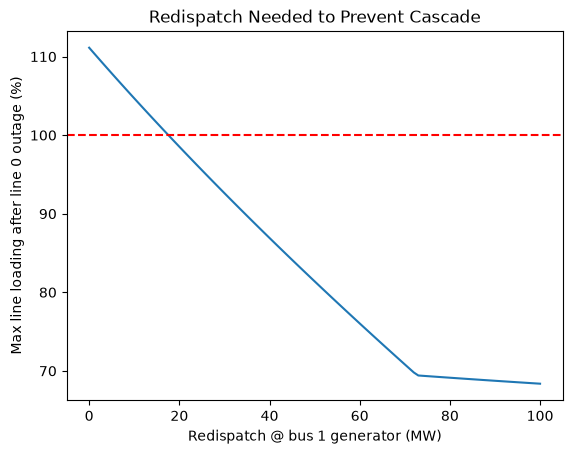

In [ ]:
# redispatch: adjusting the power output of generators to keep the grid operating safely
def redispatch(net, redispatch_mw=0, gen_bus=1):
    n = copy.deepcopy(net)
    g = n.gen.index[n.gen.bus == gen_bus][0] # generator at bus 1
    n.gen.loc[g, "p_mw"] += redispatch_mw # boost power output
    return n

def outage_result(net, line):
    n = copy.deepcopy(net)
    n.line.loc[line, "in_service"] = False
    try:
        pp.runpp(n)
        return check_case(n)
    except pp.LoadflowNotConverged:
        return {
            "Status": "Non-convergence",
            "Max_Line_Loading_%": np.nan,
            }

rows = []
for mw in range(101):
    corrected = redispatch(net, redispatch_mw=mw)
    status = sim_cascade(corrected, load_max, 0)["Cascade_Status"]
    rows.append({"Redispatch_MW": mw, 
                 "Status": status,
                 "Max_Loading": outage_result(corrected, 0)["Max_Line_Loading_%"],
                 })

sweep = pd.DataFrame(rows)

plt.plot(sweep["Redispatch_MW"], sweep["Max_Loading"])
plt.title("Redispatch Needed to Prevent Cascade")
plt.xlabel("Redispatch @ bus 1 generator (MW)")
plt.ylabel("Max line loading after line 0 outage (%)")
plt.axhline(100, linestyle="--", color="red") # mark 100% voltage limit
plt.show()


In [ ]:
# load shedding: deliberate, temporary shutdown of electric supply to selected loads 